# Evolución de la exclusión escolar infantil 2000–2025

**Autora:** Valentina Merchan Sanchez

---
# 1. Introducción y pregunta de análisis

### 1.1 Introducción
El dataset utilizado es "Out-of-school children of primary school age", publicado por
Our World in Data a partir de datos del Instituto de Estadística de la UNESCO (UIS).

**Fuente:** https://ourworldindata.org/grapher/out-of-school-children-of-primary-school-age-by-world-region
**Productor original:** UNESCO Institute for Statistics (2026)
**Licencia:** CC BY 3.0 IGO
**Última actualización:** 12 de mayo de 2026
**Fecha de descarga:** 20 de octubre de 2026

La variable mide el número de niños en la edad oficial de primaria que no están
matriculados ni en educación primaria ni secundaria. Los niños pueden no haber entrado nunca al colegio,
haber desertado o estar empezando más tarde de lo normal. Los valores son numero de
niños (no porcentajes). El archivo csv incluye países, regiones, grupos por nivel de ingreso y
el total mundial; este análisis se centra en las 7 regiones definidas para los Objetivos
de Desarrollo Sostenible (ODS), con datos anuales de 2000 a 2025.

### 1.2 Relevancia del problema
La educación primaria es un derecho y la cuarta meta central del los Objetivos de Desarrollo Sostenible. Saber cuántos niños
siguen fuera de la escuela, y dónde, indica hacia qué regiones deben dirigirse los
esfuerzos internacionales y nacionales. Además, Ver cómo ha cambiado el reparto entre regiones desde el año 2000 permite
saber si el progreso ha sido parejo o si el problema se ha concentrado en alguna región.

### 1.3 Pregunta de análisis
Entre 2000 y 2025, ¿cómo evolucionó el número de niños en edad de primaria fuera de la
escuela en las siete regiones del mundo, y se frenó la reducción global después de 2013
mientras el problema se concentraba en África Subsahariana?

---
# 2. Carga y exploración inicial
---

### 2.1 Librerias

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats
import statsmodels.api as sm


### 2.2 Carga del data set

In [85]:
URL = ("https://raw.githubusercontent.com/ValentinaMSanchez/proyecto-final-out-of-school-children/refs/heads/main/out-of-school-children-of-primary-school-age-by-world-region.csv")

df = pd.read_csv(URL)

### 2.3 Exploración básica

In [86]:
#Forma del data set
df.shape

(4368, 4)

El dataset tiene **4.368 filas y 4 columnas**. Cada fila es una observación de una entidad en un año.

In [87]:
#Primeras filas del data set
df.head()

,Entity,Code,Year,Primary
0,Afghanistan,AFG,1993,1593009.0
1,Albania,ALB,1999,8349.0
2,Albania,ALB,2000,8207.0
3,Albania,ALB,2001,7819.0
4,Albania,ALB,2003,3146.0


Las columnas son `Entity` (nombre de la entidad), `Code` (código de la entidad), `Year` (año) y `Primary` (número de niños en edad de primaria fuera de la escuela). Los datos están ordenados alfabéticamente por entidad y luego por año.

In [88]:
#Tipos de variables
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4368 entries, 0 to 4367
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Entity   4368 non-null   str    
 1   Code     4186 non-null   str    
 2   Year     4368 non-null   int64  
 3   Primary  4368 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 136.6 KB


`Entity` y `Code` son de texto, `Year` es entero y `Primary` es decimal. Aunque `Primary` representa un conteo de niños, es float. Además, `Code` tiene 4.186 valores no nulos de 4.368, así que le faltan 182 valores.

In [89]:
#Valores únicos

df.nunique()

Entity      227
Code        220
Year         40
Primary    4124
dtype: int64

Hay **227 entidades distintas** y **40 años distintos**. Hay 220 códigos distintos para 227 entidades, es decir, 7 entidades no tienen código. Esto es consistente con los 182 valores faltantes de `Code` que vimos en `info()`: si esas 7 entidades aparecen en 26 años cada una, resultan 7 × 26 = 182 filas sin código. Lo confirmamos en la sección 2.3.5.

In [90]:
#Estadísticas descriptivas

df.describe().round(0)

,Year,Primary
count,4368.0,4368.0
mean,2009.0,1959359.0
std,10.0,9554847.0
min,1986.0,0.0
25%,2003.0,3014.0
50%,2011.0,28709.0
75%,2018.0,248283.0
max,2025.0,127600000.0


Los años van de 1986 a 2025. En `Primary`, la mediana es 28.709 niños y la media supera los 1,9 millones. Esa diferencia tan grande indica una distribución muy asimétrica. El máximo es 127,6 millones.

In [91]:
df[df["Code"].isnull()]["Entity"].unique()

<StringArray>
[                    'Central and Southern Asia (SDG)',
                'Eastern and South-Eastern Asia (SDG)',
                   'Europe and Northern America (SDG)',
               'Latin America and the Caribbean (SDG)',
              'Northern Africa and Western Asia (SDG)',
 'Oceania (excluding Australia and New Zealand) (SDG)',
                            'Sub-Saharan Africa (SDG)']
Length: 7, dtype: str

Solo `Code` tiene valores faltantes (182). Al revisar a qué entidades pertenecen, vemos que son exactamente las **7 regiones**, que no tienen código de país.

### 2.4 Tipos de entidades

La columna `Entity` tiene objetos que no son paises, y necesitamos estudiar bien qué contiene. Para esto, clasificamos cada fila en cuatro tipos: países, regiones ODS (las definidas para los Objetivos de Desarrollo Sostenible), grupos por nivel de ingreso y el total mundial.

In [92]:
condiciones = [
    df["Entity"].str.contains(r"\(SDG\)"),
    df["Entity"] == "World",
    df["Code"].fillna("").str.startswith("OWID") & (df["Entity"] != "World"),
]
tipo_entidad = np.select(condiciones, ["Región ODS", "Mundo", "Grupo por ingreso"], default="País")

df.groupby(tipo_entidad).agg(
    entidades=("Entity", "nunique"),
    filas=("Year", "size"),
    Year_min=("Year", "min"),
    Year_max=("Year", "max")
)

,entidades,filas,Year_min,Year_max
Grupo por ingreso,4,104,2000,2025
Mundo,1,26,2000,2025
País,215,4056,1986,2025
Región ODS,7,182,2000,2025


El dataset contiene:

- 215 países (4.056 filas, entre 1986 y 2025).
- 7 regiones ODS (182 filas, entre 2000 y 2025).
- 4 grupos por nivel de ingreso (104 filas).
- 1 agregado mundial ("World", 26 filas).

Las regiones, los grupos por ingreso y "World" cubren el mismo periodo (2000–2025), mientras que los países empiezan en 1986. Los agregados se solapan, no deben sumarse ni promediarse juntos.

In [93]:
#Para organizar los datos, creé una variable llamada `tipo_entidad` que clasifica cada registro según el tipo de entidad geográfica o agregada que representa. Primero definí tres condiciones utilizando las columnas `Entity` y `Code´, una para identificar las regiones ODS, otra para identificar el total mundial y una tercera para reconocer los grupos cuyos códigos comienzan por `OWID`, excluyendo el mundo. Después utilicé `np.select()` para asignar una etiqueta a cada fila según la primera condición que se cumpla. Si ninguna condición se cumple, el registro se clasifica por defecto como país.

#Esta clasificación facilita separar los países de los agregados regionales y económicos, lo cual es importante para evitar comparaciones que mezclen niveles geográficos diferentes.

In [94]:
df[df["Entity"].str.contains(r"\(SDG\)")]["Entity"].unique()

<StringArray>
[                    'Central and Southern Asia (SDG)',
                'Eastern and South-Eastern Asia (SDG)',
                   'Europe and Northern America (SDG)',
               'Latin America and the Caribbean (SDG)',
              'Northern Africa and Western Asia (SDG)',
 'Oceania (excluding Australia and New Zealand) (SDG)',
                            'Sub-Saharan Africa (SDG)']
Length: 7, dtype: str

Estas son las 7 regiones sobre las que se centrará este análisis: Asia Central y del Sur, Asia Oriental y Sudoriental, Europa y América del Norte, América Latina y el Caribe, África del Norte y Asia Occidental, Oceanía (sin Australia ni Nueva Zelanda) y África Subsahariana.

### 2.5 Rango de años y cobertura

Revisamos qué años cubre el dataset y si hay huecos, primero en general y luego en las regiones.

In [95]:
print("Rango de años:", df["Year"].min(), "-", df["Year"].max())
print("Años distintos:", df["Year"].nunique())
print("¿Hay todos los años entre 1986 y 2025?", sorted(df["Year"].unique()) == list(range(1986, 2026)))

entidades_por_anio = df.groupby("Year")["Entity"].nunique()
entidades_por_anio.loc[[1986, 1998, 1999, 2000, 2010, 2020, 2024, 2025]]

Rango de años: 1986 - 2025
Años distintos: 40
¿Hay todos los años entre 1986 y 2025? True


Year
1986     55
1998     48
1999     87
2000    111
2010    140
2020    158
2024    134
2025     25
Name: Entity, dtype: int64

El dataset cubre 40 años consecutivos (1986–2025). Sin embargo, la cantidad de entidades con dato varía mucho: pasa de 55 en 1986 a 87 en 1999 y a 111 en el año 2000, llega a 158 en 2020 y cae a 134 en 2024 y solo 25 en 2025. El dato de 2025 es parcial para los países, pero las regiones sí lo tienen completo.

In [96]:
regiones = df[df["Entity"].str.contains(r"\(SDG\)")]

cobertura = regiones.groupby("Entity")["Year"].agg(n_years="count", primero="min", ultimo="max")
display(cobertura)

print("¿Todas las regiones tienen todos los años de 2000 a 2025?",
    regiones.groupby("Entity")["Year"].apply(set).eq(set(range(2000, 2026))).all())

,n_years,primero,ultimo
Entity,,,
Central and Southern Asia (SDG),26,2000,2025
Eastern and South-Eastern Asia (SDG),26,2000,2025
Europe and Northern America (SDG),26,2000,2025
Latin America and the Caribbean (SDG),26,2000,2025
Northern Africa and Western Asia (SDG),26,2000,2025
Oceania (excluding Australia and New Zealand) (SDG),26,2000,2025
Sub-Saharan Africa (SDG),26,2000,2025


¿Todas las regiones tienen todos los años de 2000 a 2025? True


Las 7 regiones tienen 26 observaciones cada una, de 2000 a 2025, sin ningún año faltante. 

In [97]:
paises = df[tipo_entidad == "País"]
paises.groupby("Entity")["Year"].count().describe()

count    215.000000
mean      18.865116
std        9.212722
min        1.000000
25%       11.000000
50%       21.000000
75%       25.000000
max       39.000000
Name: Year, dtype: float64

En contraste, los países tienen cobertura muy desigual: entre 1 y 39 años de datos, con una mediana de 21. Solo 2 países tienen los 39 años posibles. Con datos tan incompletos, comparar o sumar países año a año sería poco confiable, por lo cual, se toma la decisión de centrar el análisis en las regiones.

### 2.6 Primeras observaciones

- El archivo mezcla cuatro tipos de entidades (países, regiones, grupos por ingreso y total mundial) en una misma columna. Los cuales se solapan, así que sumarlos o promediarlos juntos contaría varias veces a los mismos niños.
- Los países tienen cobertura muy irregular (entre 1 y 39 años de datos), pero las 7 regiones tienen datos completos y sin huecos de 2000 a 2025. Esto las hace adecuada para analizar y resolver nuestra pregunta.
- La variable `Primary` tiene una distribución muy asimétrica, con valores que van desde 0 hasta 127,6 millones, porque combina países pequeños con agregados mundiales.
- Los únicos valores faltantes son los de `Code`, y corresponden a las regiones, que claramente no tienen un codigo de pais asignado

---
# 3. Limpieza y transformación
---

como se vio en la sección anterior, el dataset original mezcla países, regiones, grupos por nivel de ingreso y el total mundial. Como la pregunta de este analisis es sobre las 7 regiones del mundo.

### 3.1 Renombrando las columnas

Renombramos las columnas a nombres cortos, en minúsculas y sin tildes, que sean más claros y fáciles de usar en el código. En particular, `Primary` no dice qué contiene, y `ninos_fuera_escuela` sí. 

In [98]:
assert df.shape[1] == 4, "El CSV cambió de estructura"
df.columns = ["entidad", "codigo", "anio", "ninos_fuera_escuela"]
df.columns.tolist()

['entidad', 'codigo', 'anio', 'ninos_fuera_escuela']

### 3.2 Seleccionando las regiones

Nos quedamos solo con las 7 regiones ODS, que son las únicas entidades con datos completos de 2000 a 2025. Descartamos los países (cobertura muy irregular) y los grupos por nivel de ingreso.

El total mundial ("World") se guarda aparte porque no es una región y se usará solo para validar los datos

In [99]:
df_regiones = df[df["entidad"].str.contains(r"\(SDG\)")].copy()
df_mundo = df[df["entidad"] == "World"].copy()

print("Dataset original:", df.shape)
print("Regiones:", df_regiones.shape)
print("Total mundial:", df_mundo.shape)

Dataset original: (4368, 4)
Regiones: (182, 4)
Total mundial: (26, 4)


Pasamos de 4.368 filas a 182 filas de regiones (7 regiones × 26 años). El total mundial tiene 26 filas, una por año.

### 3.3 Simplificando los nombres de las regiones

Los nombres originales están en inglés y llevan el sufijo "(SDG)". Los reemplazamos por nombres en español, más cortos, para que los gráficos sean más legibles. Con el `assert` nos aseguramos de que el diccionario cubra exactamente las 7 regiones.

In [100]:
nombres_regiones = {
    "Central and Southern Asia (SDG)": "Asia Central y del Sur",
    "Eastern and South-Eastern Asia (SDG)": "Asia Oriental y Sudoriental",
    "Europe and Northern America (SDG)": "Europa y América del Norte",
    "Latin America and the Caribbean (SDG)": "América Latina y el Caribe",
    "Northern Africa and Western Asia (SDG)": "África del Norte y Asia Occidental",
    "Oceania (excluding Australia and New Zealand) (SDG)": "Oceanía (sin Australia ni Nueva Zelanda)",
    "Sub-Saharan Africa (SDG)": "África Subsahariana",
}

assert set(df_regiones["entidad"].unique()) == set(nombres_regiones)

df_regiones["region"] = df_regiones["entidad"].map(nombres_regiones)
df_regiones["region"].value_counts()

region
Asia Central y del Sur                      26
Asia Oriental y Sudoriental                 26
Europa y América del Norte                  26
América Latina y el Caribe                  26
África del Norte y Asia Occidental          26
Oceanía (sin Australia ni Nueva Zelanda)    26
África Subsahariana                         26
Name: count, dtype: int64

### 3.4 Tratamiento de valores faltantes

Revisamos los nulos dentro de las regiones.

In [101]:
df_regiones.isnull().sum()

entidad                  0
codigo                 182
anio                     0
ninos_fuera_escuela      0
region                   0
dtype: int64

Como ya vimos, las regiones no tienen código asignado, así que esta columna no aporta información. Se decide eliminarla, junto con `entidad`, que ya fue reemplazada por `region`. No hay valores faltantes en `anio` ni en `ninos_fuera_escuela`, por lo que no hace falta imputar nada.

In [102]:
df_regiones = df_regiones.drop(columns=["entidad", "codigo"])
df_mundo = df_mundo.drop(columns=["entidad", "codigo"])

print(df_regiones.columns.tolist())
print(df_mundo.columns.tolist())

['anio', 'ninos_fuera_escuela', 'region']
['anio', 'ninos_fuera_escuela']


### 3.5 Corrección de tipos de datos

`ninos_fuera_escuela` es de tipo decimal, pero representa un conteo de niños. Antes de convertirla a entero verificamos que no se pierda información.

In [103]:
print(df_regiones.dtypes)
print("Valores con decimales:", (df_regiones["ninos_fuera_escuela"] % 1 != 0).sum())

anio                     int64
ninos_fuera_escuela    float64
region                     str
dtype: object
Valores con decimales: 0


Como no hay valores con decimales, no "perderemos informacion" al pasar la variable de 'float' a 'int'

In [104]:
df_regiones["ninos_fuera_escuela"] = df_regiones["ninos_fuera_escuela"].astype("int64")
df_mundo["ninos_fuera_escuela"] = df_mundo["ninos_fuera_escuela"].astype("int64")

df_regiones.dtypes

anio                   int64
ninos_fuera_escuela    int64
region                   str
dtype: object

### 3.6 Duplicados, valores inconsistentes y orden

Verificamos que no haya filas duplicadas, que no exista más de una observación por región y año, y que no haya valores negativos o iguales a cero, que no tendrían sentido en un conteo de niños. Finalmente, ordenamos la tabla por región y año.

In [105]:
print("Filas duplicadas:", df_regiones.duplicated().sum())
print("Duplicados región-año:", df_regiones.duplicated(["region", "anio"]).sum())
print("Valores negativos:", (df_regiones["ninos_fuera_escuela"] < 0).sum())
print("Valores iguales a cero:", (df_regiones["ninos_fuera_escuela"] == 0).sum())

df_regiones = (df_regiones[["region", "anio", "ninos_fuera_escuela"]]
            .sort_values(["region", "anio"])
            .reset_index(drop=True))

Filas duplicadas: 0
Duplicados región-año: 0
Valores negativos: 0
Valores iguales a cero: 0


No hay duplicados, valores negativos ni ceros, por lo que no es necesario aplicar ninguna corrección. Dejamos la tabla ordenada por región y año y con las columnas en un orden lógico.

### 3.7 Validación: suma de regiones frente al total mundial

Como control de calidad, comparamos la suma de las 7 regiones con el total mundial que viene en el mismo archivo. Si los datos son coherentes, ambos valores deberían ser muy cercanos.

In [106]:
suma_regiones = df_regiones.groupby("anio")["ninos_fuera_escuela"].sum()
mundo = df_mundo.set_index("anio")["ninos_fuera_escuela"]

comparacion = pd.DataFrame({"suma_regiones": suma_regiones, "mundo": mundo})
comparacion["diferencia"] = comparacion["mundo"] - comparacion["suma_regiones"]
comparacion["diferencia_pct"] = comparacion["diferencia"] / comparacion["mundo"] * 100

display(comparacion.loc[[2000, 2013, 2025]])
print("Diferencia mínima:", comparacion["diferencia"].min())
print("Diferencia máxima:", comparacion["diferencia"].max())
print("Diferencia porcentual máxima:", round(comparacion["diferencia_pct"].max(), 2), "%")

,suma_regiones,mundo,diferencia,diferencia_pct
anio,,,,
2000,127185900,127600000,414100,0.324530
2013,79424900,79620000,195100,0.245039
2025,77807600,78570000,762400,0.970345


Diferencia mínima: 114400
Diferencia máxima: 762400
Diferencia porcentual máxima: 0.97 %


La suma de las 7 regiones queda ligeramente por debajo del total mundial, es decir, menos del 1 % del total en todos los años. Esto confirma que las regiones son coherentes con el total mundial y se pueden usar.

La diferencia puede deberse a que el archivo no incluye la región "Australia y Nueva Zelanda" (la región de Oceanía que tenemos las excluye), aunque con estos datos no podemos comprobarlo.

### 3.8 Creación de variables derivadas

Creamos variables que ayudan a responder la pregunta:

- **`ninos_millones`**: el conteo en millones de niños, para que los gráficos sean más legibles.
- **`participacion_pct`**: porcentaje que representa cada región del total de las 7 regiones en ese año. Se calcula sobre la suma de las regiones para que las participaciones sumen exactamente 100 %.
- **`indice_2000`**: valor de cada región respecto a su propio nivel en el año 2000 (2000 = 100). Permite comparar regiones de tamaños muy distintos.
- **`variacion_anual_pct`**: cambio porcentual de cada región respecto al año anterior.
- **`periodo`**: separa los años en "2000-2013" y "2014-2025". El corte en 2013 sale de observar que, a partir de ahí, el total mundial deja de caer y se estabiliza alrededor de 79 millones. Como el corte lo elegimos mirando los datos, es una hipótesis que verificaremos en las secciones siguientes.
- **`decada`**: década de cada observación.

In [107]:
# Conteo en millones
df_regiones["ninos_millones"] = df_regiones["ninos_fuera_escuela"] / 1e6

# Participación de cada región en el total de las 7 regiones
total_anual = df_regiones.groupby("anio")["ninos_fuera_escuela"].transform("sum")
df_regiones["participacion_pct"] = df_regiones["ninos_fuera_escuela"] / total_anual * 100

# Índice base 2000 = 100
base_2000 = df_regiones[df_regiones["anio"] == 2000].set_index("region")["ninos_fuera_escuela"]
df_regiones["indice_2000"] = (df_regiones["ninos_fuera_escuela"]
                              / df_regiones["region"].map(base_2000) * 100)

# Variación anual (%)
df_regiones["variacion_anual_pct"] = (df_regiones.groupby("region")["ninos_fuera_escuela"]
                                      .pct_change() * 100)

# Periodo y década
df_regiones["periodo"] = np.where(df_regiones["anio"] <= 2013, "2000-2013", "2014-2025")
df_regiones["decada"] = (df_regiones["anio"] // 10 * 10).astype(str) + "s"

df_regiones.head()

,region,anio,ninos_fuera_escuela,ninos_millones,participacion_pct,indice_2000,variacion_anual_pct,periodo,decada
0,América Latina y el Caribe,2000,3241000,3.241,2.548238,100.000000,NaN,2000-2013,2000s
1,América Latina y el Caribe,2001,2940000,2.940,2.417650,90.712743,-9.287257,2000-2013,2000s
2,América Latina y el Caribe,2002,2672000,2.672,2.299143,82.443690,-9.115646,2000-2013,2000s
3,América Latina y el Caribe,2003,2458000,2.458,2.211605,75.840790,-8.008982,2000-2013,2000s
4,América Latina y el Caribe,2004,2267000,2.267,2.096607,69.947547,-7.770545,2000-2013,2000s


In [108]:
# La participación debe sumar 100 en cada año
print("Suma de participaciones por año:", df_regiones.groupby("anio")["participacion_pct"].sum().round(6).unique())

# Valores nulos en las variables nuevas
print(df_regiones.isnull().sum())

# Participación de cada región en tres años de referencia
df_regiones.pivot(index="region", columns="anio", values="participacion_pct")[[2000, 2013, 2025]].round(1)

Suma de participaciones por año: [100.]
region                 0
anio                   0
ninos_fuera_escuela    0
ninos_millones         0
participacion_pct      0
indice_2000            0
variacion_anual_pct    7
periodo                0
decada                 0
dtype: int64


anio,2000,2013,2025
region,,,
América Latina y el Caribe,2.5,2.3,2.8
Asia Central y del Sur,43.6,33.3,23.7
Asia Oriental y Sudoriental,10.2,7.2,9.3
Europa y América del Norte,1.6,1.5,2.4
Oceanía (sin Australia ni Nueva Zelanda),0.2,0.3,0.4
África Subsahariana,32.2,44.0,50.3
África del Norte y Asia Occidental,9.8,11.3,11.2


La participación suma 100 % en todos los años, como debe ser. La única variable con valores nulos es `variacion_anual_pct`, y es porque el primer año de cada región (2000) no tiene un año anterior con el cual comparar.

Ya aquí podemos ver que la participación de África Subsahariana pasa de 32,2 % en 2000 a 50,3 % en 2025, mientras que la de Asia Central y del Sur baja de 43,6 % a 23,7 %. 

### 3.9 Dataset final

Revisamos cómo quedó el dataset limpio que usaremos en el resto del proyecto.

In [109]:
print(df_regiones.shape)
df_regiones.info()

(182, 9)
<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   region               182 non-null    str    
 1   anio                 182 non-null    int64  
 2   ninos_fuera_escuela  182 non-null    int64  
 3   ninos_millones       182 non-null    float64
 4   participacion_pct    182 non-null    float64
 5   indice_2000          182 non-null    float64
 6   variacion_anual_pct  175 non-null    float64
 7   periodo              182 non-null    str    
 8   decada               182 non-null    str    
dtypes: float64(4), int64(2), str(3)
memory usage: 12.9 KB


---
# Sección 4. Análisis exploratorio (EDA)
---

Con el dataset limpio, se puede empezar a graficar. 

Se usaron los mismos colores para cada región en todos los gráficos, para que sea fácil seguirlas.

In [110]:
import matplotlib.colors as mcolors

sns.set_theme(style="whitegrid")

# Regiones ordenadas de mayor a menor número de niños en 2025
orden_regiones = (df_regiones[df_regiones["anio"] == 2025]
                .sort_values("ninos_millones", ascending=False)["region"].tolist())

# Un color fijo por región, para usarlo en todos los gráficos
paleta = dict(zip(orden_regiones, sns.color_palette("tab10", 7)))
paleta_hex = {region: mcolors.to_hex(color) for region, color in paleta.items()}

orden_regiones

['África Subsahariana',
 'Asia Central y del Sur',
 'África del Norte y Asia Occidental',
 'Asia Oriental y Sudoriental',
 'América Latina y el Caribe',
 'Europa y América del Norte',
 'Oceanía (sin Australia ni Nueva Zelanda)']

### 4.1 Evolución del total mundial

Empezamos por ¿cuántos niños en edad de primaria están fuera de la escuela en el mundo, y cómo ha cambiado esa cifra desde el año 2000?

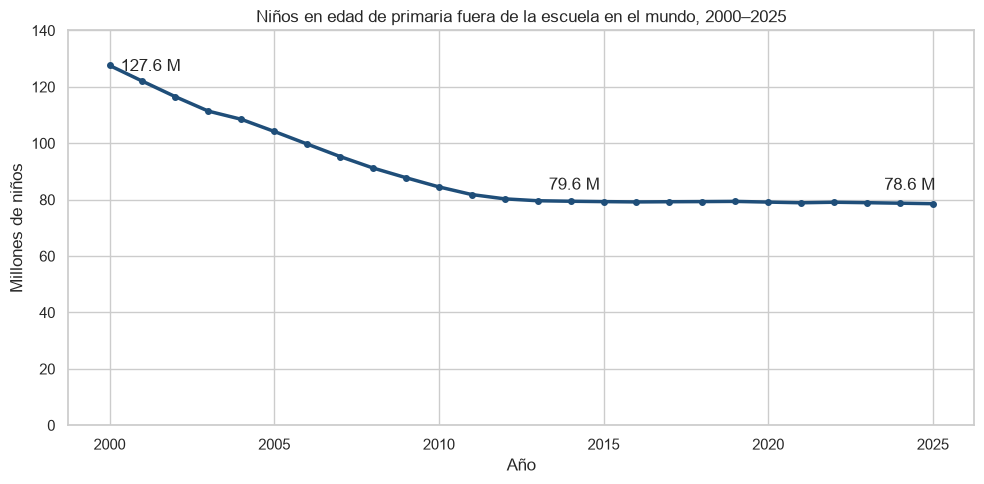

In [111]:
mundo = df_mundo.set_index("anio")["ninos_fuera_escuela"] / 1e6

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(mundo.index, mundo.values, color="#1f4e79", lw=2.5, marker="o", ms=4)


ax.annotate(f"{mundo.loc[2000]:.1f} M", (2000, mundo.loc[2000]), textcoords="offset points", xytext=(8, -4))
ax.annotate(f"{mundo.loc[2013]:.1f} M", (2013, mundo.loc[2013]), textcoords="offset points", xytext=(8, 8))
ax.annotate(f"{mundo.loc[2025]:.1f} M", (2025, mundo.loc[2025]), textcoords="offset points", xytext=(-35, 10))

ax.set_ylim(0, 140)
ax.set_title("Niños en edad de primaria fuera de la escuela en el mundo, 2000–2025")
ax.set_xlabel("Año")
ax.set_ylabel("Millones de niños")
plt.tight_layout()
plt.show()

 Entre 2000 y 2013 el total mundial cayó de 127,6 a 79,6 millones (48 millones menos, una reducción del 37,6 %). Entre 2013 y 2025, en cambio, apenas bajó 1,05 millones (1,3 %), hasta 78,6 millones, es decir la reducción global prácticamente se detuvo.

Para ilustrar esto de mejor manera, se agregó una linea punteada para marcar el año 2013, que es el punto de inflexión en la tendencia de reducción del número de niños fuera de la escuela.

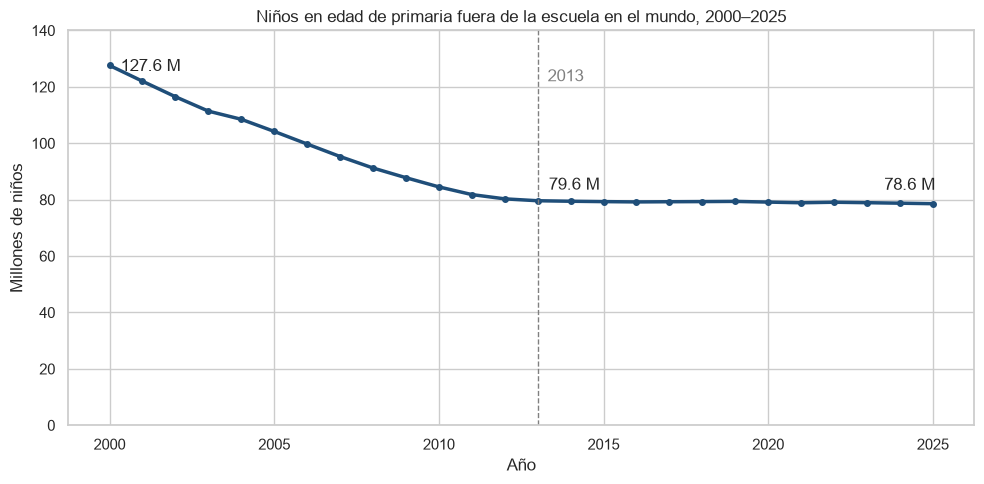

In [112]:
mundo = df_mundo.set_index("anio")["ninos_fuera_escuela"] / 1e6

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(mundo.index, mundo.values, color="#1f4e79", lw=2.5, marker="o", ms=4)
ax.axvline(2013, color="gray", ls="--", lw=1)
ax.text(2013.3, 122, "2013", color="gray")

ax.annotate(f"{mundo.loc[2000]:.1f} M", (2000, mundo.loc[2000]), textcoords="offset points", xytext=(8, -4))
ax.annotate(f"{mundo.loc[2013]:.1f} M", (2013, mundo.loc[2013]), textcoords="offset points", xytext=(8, 8))
ax.annotate(f"{mundo.loc[2025]:.1f} M", (2025, mundo.loc[2025]), textcoords="offset points", xytext=(-35, 10))

ax.set_ylim(0, 140)
ax.set_title("Niños en edad de primaria fuera de la escuela en el mundo, 2000–2025")
ax.set_xlabel("Año")
ax.set_ylabel("Millones de niños")
plt.tight_layout()
plt.show()

### 4.2 Evolución por región

El total mundial esconde diferencias entre regiones. Este gráfico interactivo (Plotly) muestra la serie de cada una. Se puede pasar el cursor para ver los valores exactos de todas las regiones en un año, y hacer clic en la leyenda para ocultar o mostrar regiones.

In [124]:
fig = px.line(
    df_regiones, x="anio", y="ninos_millones", color="region",
    category_orders={"region": orden_regiones},
    color_discrete_map=paleta_hex,
    markers=True,
    labels={"anio": "Año", "ninos_millones": "Millones de niños", "region": "Región"},
    title="Niños fuera de la escuela por región, 2000–2025"
)
fig.add_vline(x=2013, line_dash="dash", line_color="gray")
fig.update_traces(hovertemplate="%{y:.1f} millones")
fig.update_layout(hovermode="x unified", legend_title_text="Región")
fig.show()

import os
os.makedirs("figuras", exist_ok=True)
fig.write_html("figuras/evolucion_por_region.html", include_plotlyjs="cdn")

### 4.3 ¿Dónde se concentra hoy el problema?

Comparamos las regiones en el último año disponible, 2025. Junto a cada barra aparece el número de niños y su porcentaje del total de las 7 regiones.

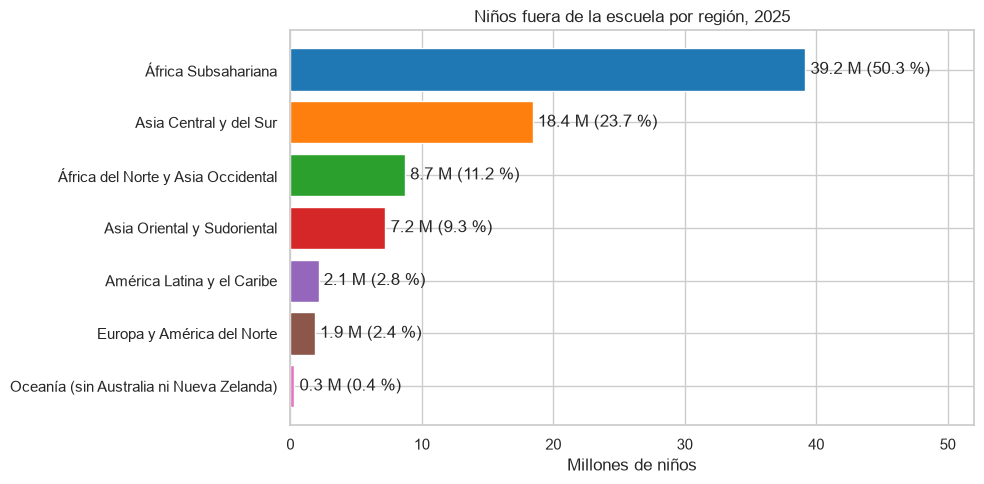

In [114]:
d25 = df_regiones[df_regiones["anio"] == 2025].sort_values("ninos_millones")

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.barh(d25["region"], d25["ninos_millones"], color=[paleta[r] for r in d25["region"]])

for barra, valor, pct in zip(barras, d25["ninos_millones"], d25["participacion_pct"]):
    ax.text(valor + 0.4, barra.get_y() + barra.get_height() / 2,
            f"{valor:.1f} M ({pct:.1f} %)", va="center")

ax.set_xlim(0, 52)
ax.set_title("Niños fuera de la escuela por región, 2025")
ax.set_xlabel("Millones de niños")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

En 2025 el problema está muy concentrado: África Subsahariana tiene 39,2 millones de niños fuera de la escuela (50,3 % del total) y Asia Central y del Sur 18,4 millones (23,7 %). Entre las dos reúnen 57,6 millones, el 74 % del total. Las otras cinco regiones suman menos de una cuarta parte.

### 4.4 ¿Cómo cambió el reparto entre regiones?

Para ver si el problema se concentró con el tiempo, graficamos la participación de cada región en el total de cada año. Cada franja es una región y el alto total siempre es 100 %.

In [126]:
fig = px.area(
df_regiones, x="anio", y="participacion_pct", color="region",
category_orders={"region": orden_regiones},
color_discrete_map=paleta_hex,
labels={"anio": "Año", "participacion_pct": "% del total de las 7 regiones", "region": "Región"},
title="Participación de cada región en el total de niños fuera de la escuela"
)
fig.update_traces(hovertemplate="%{y:.1f} %")
fig.update_layout(hovermode="x unified", legend_title_text="Región",
                yaxis=dict(range=[0, 100], ticksuffix=" %"))
fig.show()

fig.write_html("figuras/participacion_por_region.html", include_plotlyjs="cdn")

 El reparto cambió mucho. La participación de África Subsahariana subió de 32,2 % en 2000 a 44,0 % en 2013 y a 50,3 % en 2025, mientras la de Asia Central y del Sur bajó de 43,6 % a 33,3 % y luego a 23,7 %. Es decir, pasó de dominar Asia Central y del Sur a dominar África Subsahariana

### 4.5 ¿Se frenó el progreso después de 2013?

Para comparar el ritmo de cambio de cada región entre los dos periodos, se calculó el cambio promedio anual en millones de niños: los valores negativos indican que el número bajó en promedio cada año, y los positivos, que subió. El periodo 2014–2025 incluye el cambio entre 2013 y 2014.

periodo,2000-2013,2014-2025
region,,
África Subsahariana,-0.46,0.35
Asia Central y del Sur,-2.23,-0.67
África del Norte y Asia Occidental,-0.26,-0.03
Asia Oriental y Sudoriental,-0.56,0.12
América Latina y el Caribe,-0.11,0.03
Europa y América del Norte,-0.06,0.05
Oceanía (sin Australia ni Nueva Zelanda),-0.00,0.01


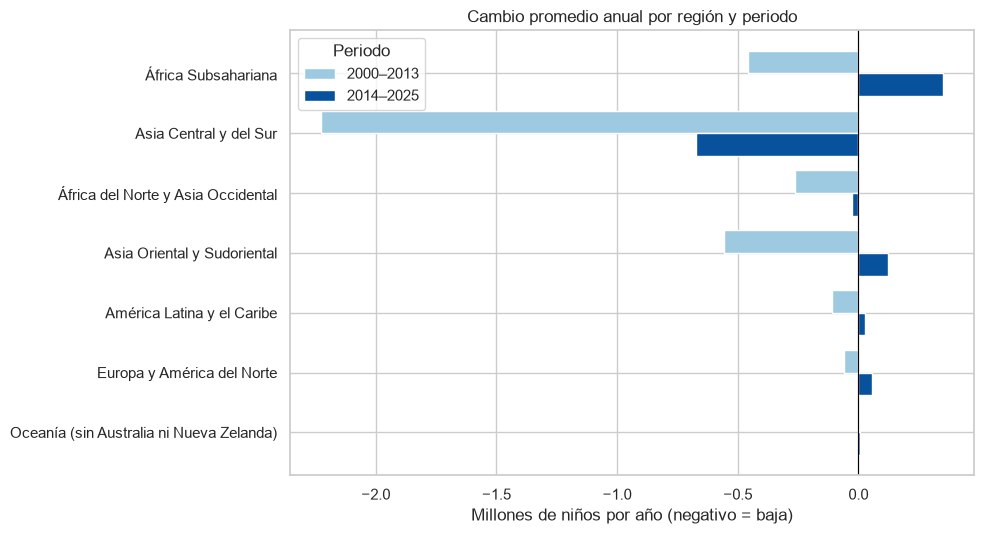

In [116]:
cambio = df_regiones.copy()
cambio["cambio_anual_millones"] = cambio.groupby("region")["ninos_millones"].diff()

cambio_periodo = (cambio.dropna(subset=["cambio_anual_millones"])
                .groupby(["region", "periodo"])["cambio_anual_millones"].mean()
                .unstack().loc[orden_regiones])

display(cambio_periodo.round(2))

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(cambio_periodo))
alto = 0.38
ax.barh(y - alto / 2, cambio_periodo["2000-2013"], alto, label="2000–2013", color="#9ecae1")
ax.barh(y + alto / 2, cambio_periodo["2014-2025"], alto, label="2014–2025", color="#08519c")
ax.set_yticks(y)
ax.set_yticklabels(cambio_periodo.index)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Cambio promedio anual por región y periodo")
ax.set_xlabel("Millones de niños por año (negativo = baja)")
ax.legend(title="Periodo")
plt.tight_layout()
plt.show()

 Entre 2000 y 2013 las 7 regiones redujeron su cifra (Oceanía muy poco). Entre 2014 y 2025 el ritmo se frenó en todas, y cinco regiones pasaron de bajar a subir, África Subsahariana, Asia Oriental y Sudoriental, América Latina y el Caribe, Europa y América del Norte, y Oceanía. Asia Central y del Sur siguió bajando, pero más lento que el ritmo anterior Ninguna región aceleró su reducción.

### 4.6 Evolución relativa de cada región

Como las regiones tienen tamaños muy distintos, comparamos su evolución con un índice que toma el valor de 2000 como 100. Un valor de 50 significa que la región redujo su cifra a la mitad; uno mayor a 100, que está por encima de su nivel de 2000. Por claridad mostramos algunos años de referencia.

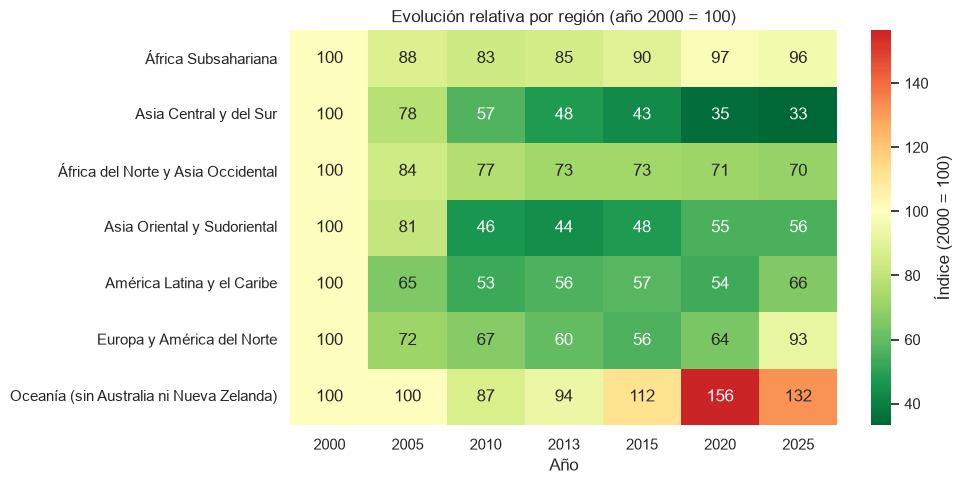

In [117]:
anios_ref = [2000, 2005, 2010, 2013, 2015, 2020, 2025]

mapa = (df_regiones[df_regiones["anio"].isin(anios_ref)]
        .pivot(index="region", columns="anio", values="indice_2000")
        .loc[orden_regiones])

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(mapa, annot=True, fmt=".0f", cmap="RdYlGn_r", center=100,
            cbar_kws={"label": "Índice (2000 = 100)"}, ax=ax)
ax.set_title("Evolución relativa por región (año 2000 = 100)")
ax.set_xlabel("Año")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Asia Central y del Sur redujo su cifra a un tercio (índice 33 en 2025) y Asia Oriental y Sudoriental a poco más de la mitad (56). África Subsahariana, en cambio, apenas bajó un 4 % en 25 años (índice 96) y estuvo mejor en 2013 (85) que hoy. Europa y América del Norte pasó de 60 en 2013 a 93 en 2025, y Oceanía supera su nivel de 2000 (132), aunque con cifras pequeñas (0,2 a 0,3 millones), por lo que su índice varía mucho con cambios mínimos.

### 4.7 Síntesis del análisis 

- El total mundial bajó con fuerza hasta 2013 y casi no se movió después.
- El progreso fue muy desigual: Asia Central y del Sur redujo su cifra a un tercio, mientras África Subsahariana casi no mejoró en 25 años.
- Hoy África Subsahariana concentra la mitad de los niños fuera de la escuela, y junto con Asia Central y del Sur reúne el 74 %.
- Después de 2013 el ritmo de reducción se frenó en todas las regiones, y en cinco de ellas la cifra empezó a subir.

---
# Sección 5. Análisis estadístico
---

La pregunta del proyecto tiene dos partes: cómo cambió el número de niños fuera de la escuela en cada región y si el ritmo de reducción se frenó después de 2013. Las pruebas de esta sección responden cada una con una herramienta distinta

El chi-cuadrado y la regresión logística no se usan, porque los datos no tienen variables categóricas ni binarias: solo hay un conteo (niños fuera de la escuela) y el tiempo.

### 5.1 Regresión lineal por región, 2000–2025

Para cada región se ajusta una recta `niños (millones) = a + b · año`. La pendiente `b` indica cuántos millones de niños aumenta (si es positiva) o disminuye (si es negativa) el número de niños fuera de la escuela **por cada año que pasa**. El **R²** indica qué proporción de la variación se explica por una tendencia lineal en el tiempo.

- *H₀:* la pendiente es cero (el número de niños no cambia linealmente con el año).
- *H₁:* la pendiente es distinta de cero.

También se calcula el **estadístico de Durbin-Watson**, que revisa si los errores del modelo son independientes. Un valor cercano a 2 indica independencia; valores cercanos a 0 indican autocorrelación positiva fuerte, algo esperable en series de tiempo.

In [118]:
def durbin_watson(residuos):
    """Durbin-Watson: ~2 = sin autocorrelación; cerca de 0 = autocorrelación positiva fuerte."""
    residuos = np.asarray(residuos)
    return np.sum(np.diff(residuos) ** 2) / np.sum(residuos ** 2)

def regresion_lineal(d):
    """Ajusta ninos_millones ~ anio para un subconjunto de datos y devuelve los resultados clave."""
    lr = stats.linregress(d["anio"], d["ninos_millones"])
    t_crit = stats.t.ppf(0.975, df=len(d) - 2)
    residuos = d["ninos_millones"] - (lr.intercept + lr.slope * d["anio"])
    return {
        "pendiente_millones_anio": lr.slope,
        "ic95_inf": lr.slope - t_crit * lr.stderr,
        "ic95_sup": lr.slope + t_crit * lr.stderr,
        "R2": lr.rvalue ** 2,
        "p_valor": lr.pvalue,
        "durbin_watson": durbin_watson(residuos),
    }

def formato_p(p):
    return "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")

reg_total = pd.DataFrame({r: regresion_lineal(df_regiones[df_regiones["region"] == r])
                        for r in orden_regiones}).T
reg_total["pendiente_ninos_anio"] = (reg_total["pendiente_millones_anio"] * 1e6).round(0).astype(int)

tabla_reg_total = reg_total[["pendiente_millones_anio", "pendiente_ninos_anio", "ic95_inf",
                            "ic95_sup", "R2", "durbin_watson"]].round(3)
tabla_reg_total["p_valor"] = reg_total["p_valor"].apply(formato_p)
tabla_reg_total

,pendiente_millones_anio,pendiente_ninos_anio,ic95_inf,ic95_sup,R2,durbin_watson,p_valor
África Subsahariana,0.099,98728,-0.015,0.213,0.118,0.101,"0,086"
Asia Central y del Sur,-1.502,-1502451,-1.680,-1.325,0.927,0.075,"< 0,001"
África del Norte y Asia Occidental,-0.122,-122443,-0.150,-0.095,0.777,0.141,"< 0,001"
Asia Oriental y Sudoriental,-0.199,-198561,-0.288,-0.109,0.467,0.099,"< 0,001"
América Latina y el Caribe,-0.030,-30202,-0.048,-0.012,0.336,0.122,"0,002"
Europa y América del Norte,-0.014,-13536,-0.030,0.003,0.107,0.194,"0,102"
Oceanía (sin Australia ni Nueva Zelanda),0.006,6464,0.004,0.009,0.576,0.340,"< 0,001"


In [119]:
comparacion_dw = []
for region in orden_regiones:
    d = df_regiones[df_regiones["region"] == region]
    lr = stats.linregress(d["anio"], d["ninos_millones"])
    residuos = d["ninos_millones"] - (lr.intercept + lr.slope * d["anio"])
    comparacion_dw.append({
        "region": region,
        "dw_funcion_propia": durbin_watson(residuos),
        "dw_statsmodels": sm.stats.durbin_watson(residuos),
    })

comparacion_dw = pd.DataFrame(comparacion_dw).set_index("region")
assert np.allclose(comparacion_dw["dw_funcion_propia"], comparacion_dw["dw_statsmodels"])
comparacion_dw.round(3)

,dw_funcion_propia,dw_statsmodels
region,,
África Subsahariana,0.101,0.101
Asia Central y del Sur,0.075,0.075
África del Norte y Asia Occidental,0.141,0.141
Asia Oriental y Sudoriental,0.099,0.099
América Latina y el Caribe,0.122,0.122
Europa y América del Norte,0.194,0.194
Oceanía (sin Australia ni Nueva Zelanda),0.340,0.340


Las pendientes están en millones de niños por año (la columna `pendiente_ninos_anio` las da en niños):

- Asia Central y del Sur tiene la caída más fuerte: unos 1,5 millones de niños menos cada año, con R² = 0,93. La recta explica casi toda su evolución.
- África del Norte y Asia Occidental baja unos 122 mil niños por año (R² = 0,78) y Asia Oriental y Sudoriental unos 199 mil (R² = 0,47).
- América Latina y el Caribe baja unos 30 mil por año (R² = 0,34, p = 0,002).
- Europa y América del Norte (p = 0,102) y África Subsahariana (p = 0,086) no tienen una pendiente significativa al 5 %. En África Subsahariana la pendiente es positiva (+99 mil por año), con un intervalo de confianza que incluye el cero y un R² de solo 0,12.
- Oceanía tiene una pendiente positiva 6 mil niños más por año.

El Durbin-Watson está entre 0,08 y 0,34 en todas las regiones, muy por debajo de 2. Los errores están fuertemente autocorrelacionados, así que los valores p y los intervalos de confianza de esta tabla son más optimistas de lo que deberían y hay que leerlos como orientativos.

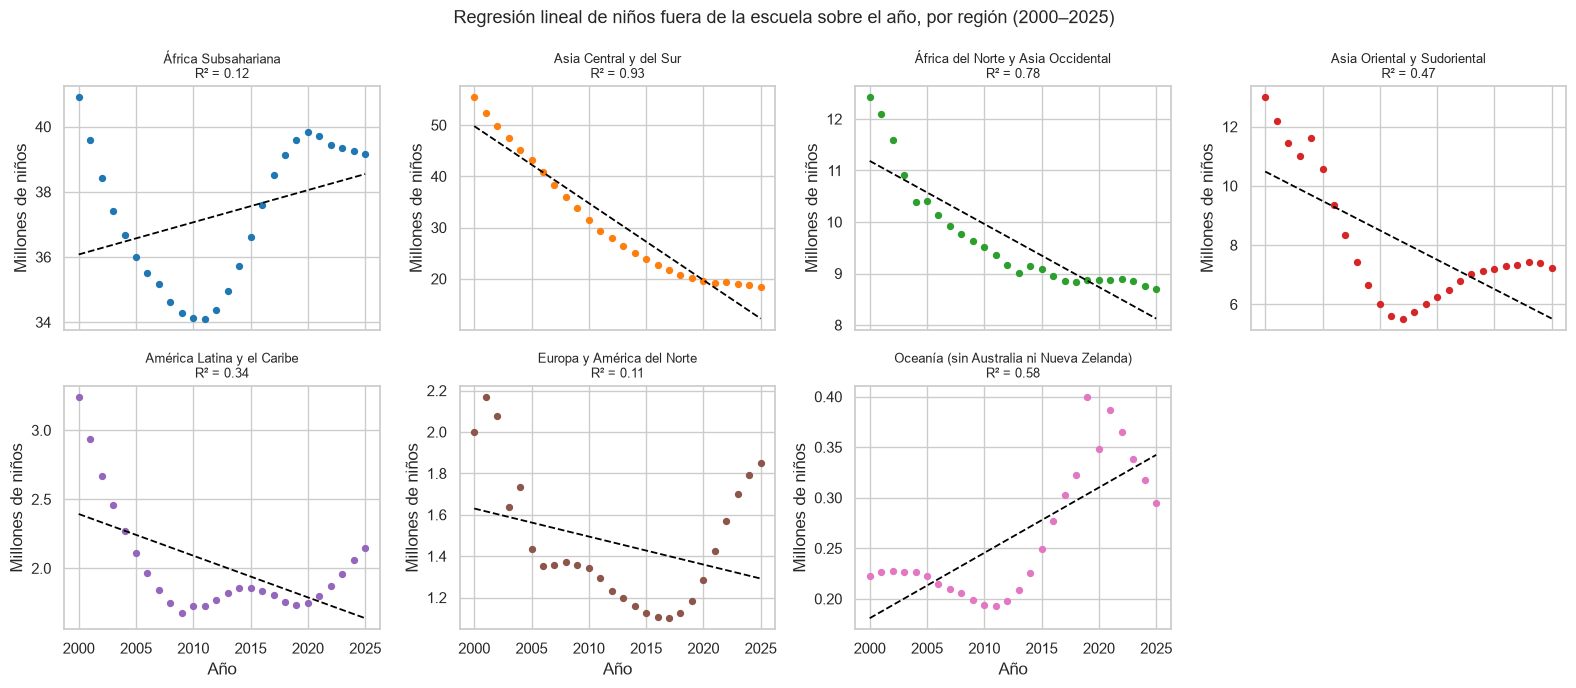

In [120]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
axes = axes.flatten()

for ax, region in zip(axes, orden_regiones):
    d = df_regiones[df_regiones["region"] == region]
    lr = stats.linregress(d["anio"], d["ninos_millones"])
    ax.scatter(d["anio"], d["ninos_millones"], color=paleta[region], s=18)
    ax.plot(d["anio"], lr.intercept + lr.slope * d["anio"], color="black", ls="--", lw=1.3)
    ax.set_title(f"{region}\nR² = {reg_total.loc[region, 'R2']:.2f}", fontsize=9)
    ax.set_ylabel("Millones de niños")

axes[-1].axis("off")
for ax in axes[4:7]:
    ax.set_xlabel("Año")
fig.suptitle("Regresión lineal de niños fuera de la escuela sobre el año, por región (2000–2025)", fontsize=13)
plt.tight_layout()
plt.show()

En Asia Central y del Sur y en África del Norte y Asia Occidental los puntos siguen la recta de cerca. En África Subsahariana, Asia Oriental y Sudoriental, América Latina y Europa y América del Norte los datos forman una "V" bajan hasta alrededor de 2010–2013 y luego suben. Una sola recta no representa esa forma. Por eso el R² de África Subsahariana es bajo (0,12) y su pendiente promedio cercana a cero no muestra que primero bajó y después subió. Lo mismo pasa con Oceanía, donde la pendiente positiva ignora que entre 2000 y 2013 la cifra bajó. Esto lleva a la siguiente sección, donde se ajusta una recta por periodo.

### 5.2 Regresión lineal por periodo: ¿cambió la pendiente después de 2013?

Como una sola recta no describe bien las regiones con forma de "V", se ajusta una regresión por separado en cada periodo definido en la sección 3.8 (2000–2013 y 2014–2025). Esto responde directamente a la segunda parte de la pregunta si el ritmo de reducción se frenó después de 2013.

In [121]:
filas = []
for region in orden_regiones:
    for periodo in ["2000-2013", "2014-2025"]:
        d = df_regiones[(df_regiones["region"] == region) & (df_regiones["periodo"] == periodo)]
        filas.append({"region": region, "periodo": periodo, **regresion_lineal(d)})

reg_periodos = pd.DataFrame(filas)

tabla_periodos = reg_periodos[["region", "periodo", "pendiente_millones_anio",
                            "ic95_inf", "ic95_sup", "R2"]].round(3)
tabla_periodos["p_valor"] = reg_periodos["p_valor"].apply(formato_p)
tabla_periodos.set_index(["region", "periodo"])

pendiente_millones_anio  \
region                                   periodo                              
África Subsahariana                      2000-2013                   -0.468   
                                         2014-2025                    0.280   
Asia Central y del Sur                   2000-2013                   -2.247   
                                         2014-2025                   -0.573   
África del Norte y Asia Occidental       2000-2013                   -0.247   
                                         2014-2025                   -0.029   
Asia Oriental y Sudoriental              2000-2013                   -0.638   
                                         2014-2025                    0.118   
América Latina y el Caribe               2000-2013                   -0.108   
                                         2014-2025                    0.022   
Europa y América del Norte               2000-2013                   -0.070   
                                         2014-2025                    0.074   
Oceanía (sin Australia ni Nueva Zelanda) 2000-2013                   -0.003   
                                         2014-2025                    0.008   

                                                    ic95_inf  ic95_sup     R2  \
region                                   periodo                                
África Subsahariana                      2000-2013    -0.610    -0.325  0.810   
                                         2014-2025     0.114     0.446  0.585   
Asia Central y del Sur                   2000-2013    -2.328    -2.166  0.997   
                                         2014-2025    -0.713    -0.433  0.893   
África del Norte y Asia Occidental       2000-2013    -0.294    -0.200  0.917   
                                         2014-2025    -0.042    -0.016  0.705   
Asia Oriental y Sudoriental              2000-2013    -0.725    -0.552  0.956   
                                         2014-2025     0.077     0.159  0.802   
América Latina y el Caribe               2000-2013    -0.142    -0.074  0.798   
                                         2014-2025     0.003     0.041  0.397   
Europa y América del Norte               2000-2013    -0.092    -0.048  0.801   
                                         2014-2025     0.053     0.095  0.857   
Oceanía (sin Australia ni Nueva Zelanda) 2000-2013    -0.004    -0.002  0.748   
                                         2014-2025    -0.001     0.017  0.290   

                                                    p_valor  
region                                   periodo             
África Subsahariana                      2000-2013  < 0,001  
                                         2014-2025    0,004  
Asia Central y del Sur                   2000-2013  < 0,001  
                                         2014-2025  < 0,001  
África del Norte y Asia Occidental       2000-2013  < 0,001  
                                         2014-2025  < 0,001  
Asia Oriental y Sudoriental              2000-2013  < 0,001  
                                         2014-2025  < 0,001  
América Latina y el Caribe               2000-2013  < 0,001  
                                         2014-2025    0,028  
Europa y América del Norte               2000-2013  < 0,001  
                                         2014-2025  < 0,001  
Oceanía (sin Australia ni Nueva Zelanda) 2000-2013  < 0,001  
                                         2014-2025    0,071

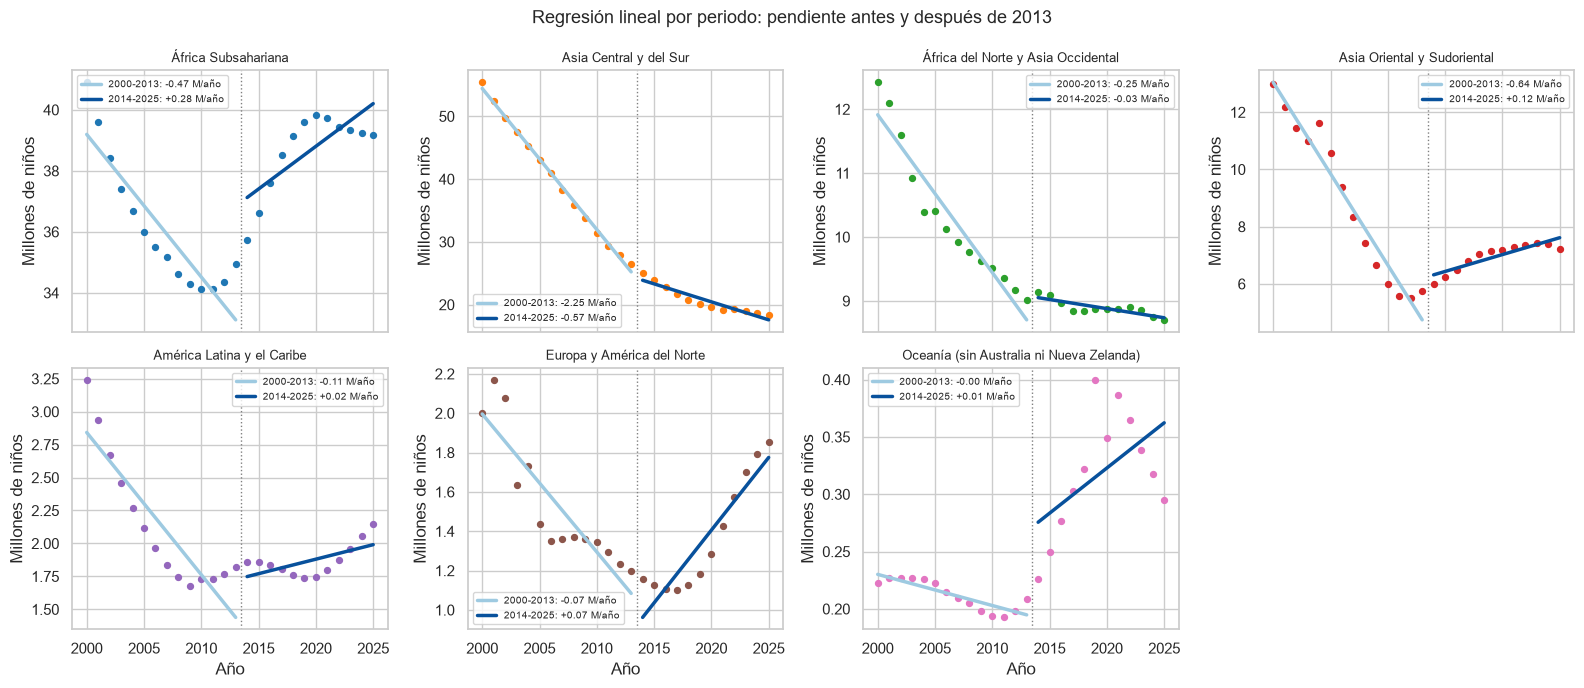

In [122]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
axes = axes.flatten()

for ax, region in zip(axes, orden_regiones):
    d = df_regiones[df_regiones["region"] == region]
    ax.scatter(d["anio"], d["ninos_millones"], color=paleta[region], s=18)
    for periodo, color in [("2000-2013", "#9ecae1"), ("2014-2025", "#08519c")]:
        dp = d[d["periodo"] == periodo]
        lr = stats.linregress(dp["anio"], dp["ninos_millones"])
        ax.plot(dp["anio"], lr.intercept + lr.slope * dp["anio"], color=color, lw=2.5,
                label=f"{periodo}: {lr.slope:+.2f} M/año")
    ax.axvline(2013.5, color="gray", ls=":", lw=1)
    ax.set_title(region, fontsize=9)
    ax.set_ylabel("Millones de niños")
    ax.legend(fontsize=7)

axes[-1].axis("off")
for ax in axes[4:7]:
    ax.set_xlabel("Año")
fig.suptitle("Regresión lineal por periodo: pendiente antes y después de 2013", fontsize=13)
plt.tight_layout()
plt.show()


- 2000–2013: las siete regiones tienen pendiente negativa y significativa (p < 0,001), con R² entre 0,75 y 0,997. La caída más rápida fue la de Asia Central y del Sur (unos 2,25 millones menos por año), seguida de Asia Oriental y Sudoriental (0,64) y África Subsahariana (0,47).
- 2014–2025: el ritmo cambió en todas las regiones.
  - Asia Central y del Sur siguió bajando, pero a unos 0,57 millones por año, cerca de una cuarta parte de su ritmo anterior.
  - África del Norte y Asia Occidental casi se estancó (−0,03 millones por año).
  - Cinco regiones pasaron de bajar a subir.*África Subsahariana sube unos 280 mil niños por año (R² = 0,59, p = 0,004). Asia Oriental y Sudoriental sube unos 118 mil y Europa y América del Norte unos 74 mil, ambas con p < 0,001. América Latina y el Caribe sube unos 22 mil (p = 0,028). Oceanía sube unos 8 mil, pero esa pendiente no es significativa (p = 0,071).

Esto coincide con lo visto en la sección 4.5 y apoya que la reducción global se frenó. El gráfico muestra además que el corte en 2013 se eligió mirando los datos, y en varias regiones el mínimo está entre 2010 y 2013 aproximadamente, así que las pendientes dependen en parte de dónde se haga el corte.

### 5.3 t-test pareado: 2000–2010 frente a 2015–2025

Para comparar el nivel (no la pendiente) de cada región entre dos épocas, se aplica un t-test pareado. Cada año de 2000–2010 se empareja con el año que ocupa la misma posición en 2015–2025 (2000 con 2015, 2001 con 2016, …, 2010 con 2025), lo que da 11 pares por región. Se excluyen 2011–2014 por ser los años de transición. Esta forma de emparejar es una convención, porque los años no son realmente "los mismos individuos medidos dos veces", y la prueba equivale a comparar los promedios de los dos periodos.

Para cada región, con *d = valor 2015–2025 − valor 2000–2010*:

- *H₀:* la diferencia media entre los dos periodos es cero (μ_d = 0).
- *H₁:* la diferencia media es distinta de cero (μ_d ≠ 0).

Como se hacen 7 pruebas (una por región), se reporta también el valor p corregido por **Bonferroni** (p × 7), para no sobreestimar la significancia por repetir pruebas. Se agrega el **d de Cohen** como tamaño del efecto y la prueba de **Wilcoxon** como verificación que no supone normalidad.

In [123]:
filas = []
for region in orden_regiones:
    serie = df_regiones[df_regiones["region"] == region].set_index("anio")["ninos_millones"]
    p1 = serie.loc[2000:2010].to_numpy()
    p2 = serie.loc[2015:2025].to_numpy()
    assert len(p1) == len(p2) == 11

    t, p = stats.ttest_rel(p2, p1)
    dif = p2 - p1
    filas.append({
        "region": region,
        "media_2000_2010": p1.mean(),
        "media_2015_2025": p2.mean(),
        "diferencia_media": dif.mean(),
        "t": t,
        "p_valor": p,
        "p_bonferroni": min(p * len(orden_regiones), 1),
        "d_cohen": dif.mean() / dif.std(ddof=1),
        "p_wilcoxon": stats.wilcoxon(p2, p1).pvalue,
    })

ttest = pd.DataFrame(filas).set_index("region")

tabla_ttest = ttest[["media_2000_2010", "media_2015_2025", "diferencia_media", "t", "d_cohen"]].round(2)
for col in ["p_valor", "p_bonferroni", "p_wilcoxon"]:
    tabla_ttest[col] = ttest[col].apply(formato_p)
tabla_ttest["significativo_bonferroni"] = np.where(ttest["p_bonferroni"] < 0.05, "Sí", "No")
tabla_ttest

,media_2000_2010,media_2015_2025,diferencia_media,t,d_cohen,p_valor,p_bonferroni,p_wilcoxon,significativo_bonferroni
region,,,,,,,,,
África Subsahariana,36.61,38.93,2.32,2.46,0.74,"0,033","0,234","0,044",No
Asia Central y del Sur,43.08,20.34,-22.74,-12.31,-3.71,"< 0,001","< 0,001","< 0,001",Sí
África del Norte y Asia Occidental,10.62,8.87,-1.74,-6.19,-1.87,"< 0,001","< 0,001","< 0,001",Sí
Asia Oriental y Sudoriental,9.79,7.05,-2.73,-3.38,-1.02,"0,007","0,049","0,014",Sí
América Latina y el Caribe,2.24,1.87,-0.37,-2.02,-0.61,"0,070","0,493","0,123",No
Europa y América del Norte,1.62,1.39,-0.23,-1.32,-0.40,"0,216","1,000","0,240",No
Oceanía (sin Australia ni Nueva Zelanda),0.22,0.33,0.11,7.73,2.33,"< 0,001","< 0,001","< 0,001",Sí



- Se rechaza H₀ con claridad (incluso tras Bonferroni) en tres regiones:
  - Asia Central y del Sur, que pasó de 43,1 a 20,3 (22,7 millones menos), con un efecto muy grande (d ≈ −3,7).
  - África del Norte y Asia Occidental, que apaso de 10,6 a 8,9.
  - Oceanía que paso de 0,22 a 0,33. Lo que es un aumento, aunque en cifras pequeñas.
- Asia Oriental y Sudoriental (9,8 → 7,1) es el caso límite: p = 0,007 y, tras Bonferroni, 0,049.
- África Subsahariana (36,6 → 38,9, unos 2,3 millones más) tiene p = 0,033, pero tras Bonferroni queda en 0,234, así que la evidencia no es robusta. Aun así, es la única región grande cuyo nivel promedio no bajó entre ambas épocas.
- América Latina y el Caribe (p = 0,070) y Europa y América del Norte (p = 0,216) no muestran diferencia significativa.

La prueba de Wilcoxon da conclusiones coherentes con las del t-test.

Como las observaciones de una misma serie están fuertemente autocorrelacionadas ( lo vimos por Durbin-Watson en 5.1), los 11 pares no son independientes, y los valores p de esta prueba también son optimistas.

### 5.4 Síntesis del análisis estadístico

- Las regresiones por periodo muestran que el ritmo cambió en todas las regiones: entre 2000 y 2013 todas bajaban de forma significativa, y después de 2013 cinco pasaron a subir (aunque en Oceanía no es significativo), Asia Central y del Sur bajó mucho más lento y África del Norte y Asia Occidental casi se estancó.
- África Subsahariana pasó de bajar unos 468 mil niños por año a subir unos 280 mil por año. Su nivel promedio en 2015–2025 es superior al de 2000–2010 (aunque esa diferencia no resiste la corrección de Bonferroni).
- Una sola recta para 2000–2025 describe bien solo a las regiones con caída sostenida (Asia Central y del Sur, y África del Norte y Asia Occidental). Para las demás, que tienen forma de "V", es mejor analizar por periodo.
- Todos los valores p y los intervalos de confianza se interpretan con cautela: las series tienen autocorrelación fuerte (Durbin-Watson entre 0,08 y 0,34) y hay solo 7 regiones. Estas y otras limitaciones se desarrollan en la sección de conclusiones.

---
# Sección 6. Uso de IA documentado
---

Durante este proyecto usé Claude (Anthropic) como herramienta de apoyo, junto con mi propio criterio para decidir qué aceptar, qué corregir y qué descartar. Lo usé como apoyo para resolver problemas técnicos y para entender teoría estadística. La pregunta de análisis, la elección del dataset y las decisiones sobre qué mostrar fueron mías.

### 6.1 En qué me ayudó la IA

- Solucionar problemas con la importación del dataset.
- Escribir y revisar el código de limpieza.
- Detectar y entender errores de sintaxis.
- Entender teoría estadística y matemática detrás de las pruebas que usé, como el estadístico de Durbin-Watson y el t-test pareado.

### 6.2 Registro detallado: qué pedí, qué me dio y qué ajusté

| Tema | Qué le pedí | Qué me dio | Qué corregí o ajusté |
|---|---|---|---|
| Importación del dataset | tuve problemas con la importacion del dataset desde la pagina oficial | Claude propuso subir el archivo csv desde mi pc | Decidí que no era lo mas optimo por el tema de reproducibilidad, así que decidi hacer el repositorio en github|
| Código de limpieza (sección 3) | Pedí verificar si mi decision de usar las regiones era la correcta| Recibí instrucciones de como proseguir y codigo en parte de la sección 2 y 3| Me sugirió añadir otro dataset para poder hacer un analisis teniendo tambien la poblacion de cada pais, pero como decidi usar las regiones, no me parecio relevante|
| Durbin-Watson | Que me explicara qué mide el estadístico y cómo interpretarlo en series de tiempo | La fórmula (suma de las diferencias al cuadrado de los residuos dividida entre la suma de los residuos al cuadrado), que un valor cercano a 2 indica independencia y uno cercano a 0 autocorrelación positiva | Verifiqué el calculo usando tambien stats, ya que claude no puede correr stats en su entorno de ejecución|
| Regresión lineal por región | Código para la regresión de niños fuera de la escuela sobre el año, con interpretación de pendiente y R² | Regresión por región con `scipy`, intervalos de confianza y gráficos | Los resultados de 5.1 mostraron que una sola recta no describe a las regiones con forma de "V" (por ejemplo, África Subsahariana, con R² de 0,12), así que se agregó 5.2 con una regresión por periodo (2000–2013 y 2014–2025) |
| t-test pareado | Que me ayudara a comparar cada región entre 2000–2010 y 2015–2025 | Código con `ttest_rel`, hipótesis nula y alternativa, y la advertencia de que emparejar año con año es una convención | Se agregó la corrección de Bonferroni (7 pruebas), el d de Cohen y la prueba de Wilcoxon como verificación. Con Bonferroni, África Subsahariana dejó de ser significativa (p de 0,033 a 0,234) |
| Creación de tablas como esta | Organizar la información en una tabla organizada teniendo en cuenta nuestra conversacion| Tabla como esta organizada y con filas y columnas definidas y espacios para completar con mi propia información | Completé toda la sección de "Qué hice yo" y arreglé errores de redacción.|

### 6.3 Dónde la IA se equivocó o hubo que ajustar su propuesta

- Al recomendarme subir el dataset desde local
- Una regresión lineal sobre todo el periodo 2000–2025 no representa bien la serie de varias regiones. Los gráficos de 5.1 lo mostraron y por eso se agregó el análisis por periodo.
- Algunos codigos eran sobrecomplicados

### 6.4 Criterio propio

- Yo definí la pregunta de análisis, elegí el dataset y decidí centrarme en las 7 regiones ODS porque son las únicas con datos completos de 2000 a 2025.
- Yo propuse el corte en 2013 a partir de lo que observé en los datos, y lo traté como hipótesis a verificar.
- Descarté el chi-cuadrado y la regresión logística porque los datos no tienen variables categóricas ni binarias.
- Escribí las interpretaciones de las tablas y gráficos.
- Decidí por mi cuenta hacer el repositorio en github ya que me pareció la solucion más rapida a mi problema.

### 6.5 Qué aprendí del proceso

La IA acelera el código y ayuda a entender la teoría, pero sus resultados hay que comprobarlos contra los datos. Por ejemplo, un R² alto o un valor p pequeño no bastan en series de tiempo con autocorrelación fuerte.

---
# Sección 7. Conclusiones
---

### 7.1 Respuesta a la pregunta de análisis

> *Entre 2000 y 2025, ¿cómo evolucionó el número de niños en edad de primaria fuera de la escuela en las siete regiones del mundo, y se frenó la reducción global después de 2013 mientras el problema se concentraba en África Subsahariana?*

Sí, ambas cosas ocurrieron

* 1. El total mundial pasó de 127,6 millones en 2000 a 79,6 millones en 2013 (48 millones menos, una caída del 37,6 %). Entre 2013 y 2025 apenas bajó 1,05 millones (1,3 %), hasta 78,6 millones. Las regresiones por periodo confirman que el ritmo cambió en todas las regiones: entre 2000 y 2013 las siete bajaban de forma significativa (p < 0,001), y después de 2013 cinco pasaron a subir (en Oceanía el aumento no es significativo), Asia Central y del Sur siguió bajando a una cuarta parte de su ritmo anterior y África del Norte y Asia Occidental casi se estancó.

* 2.  Su participación pasó de 32,2 % en 2000 a 44,0 % en 2013 y a 50,3 % en 2025 (39,2 millones de niños). Entre esa región y Asia Central y del Sur suman el 74 % del total.

* 3. Esa concentración tiene dos causas, 
- Por un lado, África Subsahariana dejó de mejorar. Pasó de bajar unos 468 mil niños por año (2000–2013) a subir unos 280 mil por año (2014–2025, p = 0,004). En 2025 su cifra está solo un 4 % por debajo de la de 2000 (índice 96) y por encima de la de 2013 (índice 85). El t-test pareado va en la misma línea (36,6 millones de promedio en 2000–2010 frente a 38,9 en 2015–2025), aunque esa diferencia no resiste la corrección de Bonferroni.
- Por otro lado, el resto del mundo mejoró, sobre todo Asia Central y del Sur, que redujo su cifra a un tercio (índice 33) y bajó su participación de 43,6 % a 23,7 %. Esa caída compensó casi por completo los aumentos de las demás regiones: las pendientes de 2014–2025 suman cerca de −0,1 millones de niños por año, lo que explica por qué el total mundial casi no se movió.

### 7.2 Limitaciones

- No se puede saber qué países explican los cambios de cada región ni si el aumento en África Subsahariana es generalizado o se debe a unos pocos países. En los datos originales los países tienen cobertura muy irregular (entre 1 y 39 años), por eso no fue posible hacer el análisis a ese nivel.
- La variable es un número de niños, no un porcentaje de la población de esa edad. Un aumento puede reflejar que hay más niños en edad escolar (crecimiento demográfico) y no necesariamente que una proporción mayor quede fuera de la escuela. Este análisis no permite separar ambos efectos.
- Los valores sucesivos de una misma región no son independientes: el estadístico de Durbin-Watson está entre 0,08 y 0,34 (lejos de 2), lo que indica autocorrelación positiva fuerte. Por eso los valores p y los intervalos de confianza son optimistas y un R² alto no basta para validar un modelo. Además hay solo 7 regiones y 11 pares de años por prueba, y los 11 pares del t-test tampoco son independientes entre sí.
- Varias regiones tocan su mínimo entre 2010 y 2013 aproximadamente, así que las pendientes por periodo dependen en parte de dónde se haga el corte. Por eso tratamos 2013 como hipótesis a verificar y no como un hecho.
-  Las cifras son estimaciones del Instituto de Estadística de la UNESCO, que pueden cambiar. Además, el dato de 2025 es parcial a nivel de países (las regiones sí lo tienen completo) y la suma de las 7 regiones queda ligeramente por debajo del total mundial (menos del 1 %).
- El análisis describe cuándo y dónde cambió el número de niños, pero no incluye variables explicativas (pobreza, conflictos, inversión educativa, políticas, demografía). No se puede afirmar por qué se frenó la reducción.

### 7.3 Recomendación

Mis conclusiones despues de hacer este analisis, son concentrar los esfuerzos de inclusión escolar en África Subsahariana, ya que es la región con más niños fuera de la escuela (39,2 millones, el 50,3 % del total mundial), la única de las dos grandes cuyo número volvió a crecer después de 2013, y el principal obstáculo para que el total mundial vuelva a bajar.

Esta recomendación se apoya en dónde está el problema y en cómo evolucionó, no en qué lo causa, porque eso este análisis no lo puede responder.Antes de diseñar acciones, haría falta trabajar con datos por país y con tasas (no solo conteos) para identificar dónde se concentra el aumento dentro de la región y separar el efecto del crecimiento de la población.